# CredAIR — Análise de Risco de Crédito

**Objetivo:** usar o histórico de propostas de crédito da CredAIR para entender os fatores ligados à inadimplência e construir um modelo de **Regressão Logística** que ajude a identificar propostas de maior risco.

> Os dados são **sintéticos** e foram criados para fins educacionais.

### Roteiro do notebook

| Seção | Conteúdo | Camada de dados |
|---|---|---|
| 1 | Entendimento do problema | 🥉 bronze |
| 2 | Diagnóstico de qualidade dos dados | 🥉 bronze |
| 3 | Limpeza e preparação | 🥉 → 🥈 prata |
| 4 | Análise exploratória | 🥈 prata |
| 5 | Engenharia de atributos | 🥈 → 🥇 ouro |
| 6 | Preparação para modelagem | 🥇 ouro |
| 7 | Modelagem | 🥇 ouro |
| 8 | Avaliação e interpretação | — |
| 9 | Conclusão | — |

Ao longo do notebook, cada decisão importante aparece num bloco **🧭 Decisão**, com o que foi feito, por quê e qual alternativa foi descartada.

## 0. Configuração do ambiente

Importamos as bibliotecas e fixamos uma **semente aleatória** (`RANDOM_STATE`). Com ela, a divisão treino/teste e o treinamento produzem sempre os mesmos resultados, o que torna a análise **reprodutível**.

As regras validadas neste notebook (limpeza, atributos, pipeline do modelo e escolha do limiar) ficam no pacote **`credair`**, na pasta `src/`, e são cobertas por testes automatizados em `tests/`. O notebook **importa** essas funções. Assim, a análise e a futura aplicação usam exatamente o mesmo código. O pacote é instalado junto com o `requirements.txt`.

In [1]:
import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from credair.config import BRONZE, FIGURAS, OURO, PRATA, RAIZ, RANDOM_STATE

# Caminhos das camadas e semente aleatória ficam em src/credair/config.py
FIGURAS.mkdir(parents=True, exist_ok=True)

# Estilo dos gráficos: fundo limpo, grade discreta e duas cores fixas para as classes
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#898781"
CORES_CLASSE = {0: AZUL, 1: LARANJA}
sns.set_theme(style="whitegrid", rc={"grid.color": "#e1e0d9", "axes.edgecolor": "#c3c2b7"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)


def salvar(fig, nome):
    # Salva a figura em reports/figures para usar na apresentação
    fig.savefig(FIGURAS / f"{nome}.png", dpi=120, bbox_inches="tight")

## 1. Entendimento do problema

### 1.1 Carregando os dados brutos (camada bronze)

Lemos o arquivo **exatamente como foi recebido**. Nenhuma alteração é feita nesta etapa.

In [2]:
bronze = pd.read_csv(BRONZE)
print(f"Linhas: {bronze.shape[0]:,} | Colunas: {bronze.shape[1]}")
bronze.head()

Linhas: 5,000 | Colunas: 11


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,"2,911.820",14,690,"5,934.190",60,Viagem,1,0
1,49,RR,Ensino Médio,"3,176.430",5,676,"6,791.380",24,Outros,2,0
2,48,AL,Ensino Superior,"3,429.400",23,558,"14,666.780",24,Outros,5,1
3,59,GO,Ensino Fundamental,"10,096.700",2,739,"19,053.240",24,Reforma,0,0
4,37,RJ,Ensino Fundamental,"3,033.250",24,797,"6,171.310",6,Educação,0,1


### 1.2 Dicionário de dados

| Coluna | Tipo | Papel | Descrição |
|---|---|---|---|
| `idade` | numérica | explicativa | Idade do solicitante na proposta |
| `estado` | categórica | explicativa | UF de residência |
| `escolaridade` | categórica **ordinal** | explicativa | Nível de escolaridade declarado |
| `renda_mensal` | numérica | explicativa | Renda mensal declarada (R$) |
| `tempo_emprego_anos` | numérica | explicativa | Anos no emprego atual |
| `score_credito` | numérica | explicativa | Pontuação de crédito do solicitante |
| `valor_solicitado` | numérica | explicativa | Valor do empréstimo (R$) |
| `prazo_meses` | numérica discreta | explicativa | Prazo de pagamento (meses) |
| `finalidade` | categórica | explicativa | Finalidade do empréstimo |
| `dividas_ativas` | numérica discreta | explicativa | Quantidade de dívidas em aberto |
| **`inadimplente`** | **binária (0/1)** | **resposta** | **1 = a proposta resultou em inadimplência** |

> **Divergência no enunciado:** o texto cita o arquivo `credito.csv`, mas o arquivo fornecido se chama `dataset.csv`. Mantivemos o nome original para preservar a rastreabilidade do dado bruto.

### 1.3 Variável resposta e tipo de problema

- **Variável resposta:** `inadimplente`. Indica se a proposta, **depois de acompanhada ao longo do tempo**, resultou em falta de pagamento (`1`) ou não (`0`).
- **Por que é Machine Learning supervisionado:** temos exemplos históricos **com a resposta conhecida**. O modelo aprende a relação entre as características da proposta e o resultado observado.
- **Por que é classificação, e não regressão:** a resposta é uma **categoria** (inadimplente ou não), e não uma quantidade contínua. Mais precisamente, é uma **classificação binária**.
- **O que o modelo vai entregar:** a Regressão Logística estima a **probabilidade** de inadimplência, um número entre 0 e 1. Para virar uma decisão (aprovar, recusar ou analisar), essa probabilidade é comparada com um **limiar**, que vamos discutir na seção 8.

### 1.4 O custo dos erros

No crédito, os dois tipos de erro **não custam o mesmo**:

| Erro | O que acontece | Custo para a CredAIR |
|---|---|---|
| **Falso negativo:** o modelo diz "bom pagador", mas a pessoa fica inadimplente | Empréstimo aprovado e não pago | **Perda do capital emprestado** (alto) |
| **Falso positivo:** o modelo diz "risco", mas a pessoa pagaria | Proposta recusada sem necessidade | Perda dos juros que seriam recebidos e do cliente (moderado) |

Por isso, na avaliação, **não basta olhar a acurácia**. Vamos dar atenção especial ao **recall da classe inadimplente**, ou seja, a fração dos maus pagadores que o modelo consegue identificar.

In [3]:
contagem = bronze["inadimplente"].value_counts().sort_index()
pd.DataFrame({
    "quantidade": contagem,
    "proporção": (contagem / contagem.sum()).map("{:.1%}".format),
}).rename(index={0: "0 - adimplente", 1: "1 - inadimplente"})

,quantidade,proporção
inadimplente,,
0 - adimplente,3280,65.6%
1 - inadimplente,1720,34.4%


**Primeira leitura:** cerca de **34%** das propostas resultaram em inadimplência. As classes são **moderadamente desbalanceadas**. Um "modelo" que dissesse sempre "adimplente" acertaria cerca de 66% das vezes sem aprender nada. Por isso a acurácia sozinha engana, e vamos comparar o modelo com essa referência na seção 7.

## 2. Diagnóstico de qualidade dos dados

Antes de corrigir qualquer coisa, fazemos um **inventário dos problemas**.

> 🧭 **Decisão: diagnosticar antes de tratar.** Separar as duas etapas evita "consertar" algo sem entender a causa e permite justificar cada tratamento com evidências. A alternativa descartada foi limpar enquanto explorávamos, o que mistura descobertas com correções e dificulta auditar.

### 2.1 Tipos e valores ausentes

In [4]:
pd.DataFrame({
    "tipo": bronze.dtypes.astype(str),
    "nulos": bronze.isna().sum(),
    "valores_distintos": bronze.nunique(),
})

,tipo,nulos,valores_distintos
idade,int64,0,73
estado,str,0,85
escolaridade,str,0,4
renda_mensal,float64,0,4921
tempo_emprego_anos,int64,0,32
score_credito,int64,0,428
valor_solicitado,float64,0,4937
prazo_meses,int64,0,7
finalidade,str,0,6
dividas_ativas,int64,0,8


Não há valores nulos **explícitos**. Mas isso não garante que os dados estejam corretos: um problema pode aparecer como valor inválido em vez de vazio. Vamos verificar.

### 2.2 Estatísticas descritivas

In [5]:
bronze.describe().T

,count,mean,std,min,25%,50%,75%,max
idade,"5,000.000",47.767,31.646,18.000,32.000,46.000,61.000,750.000
renda_mensal,"5,000.000","5,228.634","3,968.478",100.000,"2,697.320","4,146.300","6,458.877","44,814.190"
tempo_emprego_anos,"5,000.000",12.662,7.518,1.000,6.000,13.000,19.000,74.000
score_credito,"5,000.000",652.481,84.817,335.000,594.000,653.000,710.000,850.000
valor_solicitado,"5,000.000","14,264.657","8,268.261","1,721.480","8,467.170","12,365.630","17,764.885","50,000.000"
prazo_meses,"5,000.000",29.922,15.483,6.000,18.000,24.000,36.000,60.000
dividas_ativas,"5,000.000",1.900,1.865,0.000,0.000,1.000,3.000,7.000
inadimplente,"5,000.000",0.344,0.475,0.000,0.000,0.000,1.000,1.000


Alguns sinais aparecem já na tabela:
- `idade` chega a **750 anos**.
- `tempo_emprego_anos` chega a **74 anos**.
- `renda_mensal` tem mínimo de **R$ 100**.

### 2.3 Duplicidades

In [6]:
n_dup = bronze.duplicated().sum()
print(f"Linhas duplicadas (idênticas em todas as colunas): {n_dup}")
bronze[bronze.duplicated(keep=False)].sort_values(list(bronze.columns)).head(6)

Linhas duplicadas (idênticas em todas as colunas): 19


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
813,20,RN,Ensino Superior,"7,393.680",13,826,"20,006.350",36,Reforma,2,0
3723,20,RN,Ensino Superior,"7,393.680",13,826,"20,006.350",36,Reforma,2,0
2748,23,SC,Ensino Médio,"5,657.970",3,718,"6,468.510",36,Reforma,1,0
4726,23,SC,Ensino Médio,"5,657.970",3,718,"6,468.510",36,Reforma,1,0
2177,25,AC,Ensino Médio,"4,663.760",10,715,"12,020.380",36,Veículo,0,0
3089,25,AC,Ensino Médio,"4,663.760",10,715,"12,020.380",36,Veículo,0,0


Há linhas **idênticas em todas as 11 colunas**, inclusive renda e valor com centavos. A chance de duas propostas diferentes coincidirem em tudo isso é praticamente nula. Isso indica **registro duplicado**, e não dois clientes iguais.

### 2.4 Categorias: inconsistências de formatação

In [7]:
for col in ["estado", "escolaridade", "finalidade"]:
    valores = bronze[col]
    com_espaco = (valores != valores.str.strip()).sum()
    print(f"{col:13s} | categorias distintas: {valores.nunique():3d} | "
          f"após remover espaços: {valores.str.strip().nunique():3d} | registros com espaços: {com_espaco}")

print("\nExemplos:", bronze.loc[bronze["estado"] != bronze["estado"].str.strip(), "estado"].map(repr).unique()[:6])

estado        | categorias distintas:  85 | após remover espaços:  27 | registros com espaços: 101
escolaridade  | categorias distintas:   4 | após remover espaços:   4 | registros com espaços: 0
finalidade    | categorias distintas:   6 | após remover espaços:   6 | registros com espaços: 0

Exemplos: <ArrowStringArray>
['' DF '', '' PA '', '' BA '', '' PI '', ''  CE '', '' AM  '']
Length: 6, dtype: str


A coluna `estado` tem espaços extras (ex.: `' MG '`). Para o computador, `' MG '` e `'MG'` são categorias **diferentes**, o que criaria estados "fantasmas" na análise. As outras colunas categóricas estão corretas.

### 2.5 Regras de domínio: valores impossíveis ou suspeitos

Comparamos os dados com **regras do mundo real**.

In [8]:
idade_valida = bronze["idade"].between(18, 100)

regras = {
    "idade fora de 18–100 anos": ~idade_valida,
    "tempo de emprego ≥ idade": bronze["tempo_emprego_anos"] >= bronze["idade"],
    "começou a trabalhar antes dos 14 anos (idade válida)":
        idade_valida & (bronze["tempo_emprego_anos"] > bronze["idade"] - 14),
    "renda mensal < R$ 600": bronze["renda_mensal"] < 600,
    "score fora de 0–1000": ~bronze["score_credito"].between(0, 1000),
    "valor solicitado ≤ 0": bronze["valor_solicitado"] <= 0,
    "dívidas ativas < 0": bronze["dividas_ativas"] < 0,
}
pd.DataFrame({"registros": {k: int(v.sum()) for k, v in regras.items()}})

,registros
idade fora de 18–100 anos,15
tempo de emprego ≥ idade,8
começou a trabalhar antes dos 14 anos (idade válida),696
renda mensal < R$ 600,10
score fora de 0–1000,0
valor solicitado ≤ 0,0
dívidas ativas < 0,0


In [9]:
print("Idades fora do intervalo:", sorted(bronze.loc[~idade_valida, "idade"]))
print("Rendas abaixo de R$ 600:  ", sorted(bronze.loc[bronze["renda_mensal"] < 600, "renda_mensal"]))
print("\nValores que se repetem muito (possíveis valores 'padrão' ou tetos):")
print("  renda = 900:    ", (bronze["renda_mensal"] == 900).sum(), "registros")
print("  renda = 30.000: ", (bronze["renda_mensal"] == 30000).sum(), "registros")
print("  valor = 50.000: ", (bronze["valor_solicitado"] == 50000).sum(), "registros")

Idades fora do intervalo: [210, 280, 300, 340, 360, 430, 440, 500, 540, 660, 670, 680, 700, 710, 750]
Rendas abaixo de R$ 600:   [100.0, 150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0, 500.0, 550.0]

Valores que se repetem muito (possíveis valores 'padrão' ou tetos):
  renda = 900:     34 registros
  renda = 30.000:  8 registros
  valor = 50.000:  32 registros


In [10]:
# Onde estão os casos de "começou a trabalhar antes dos 14 anos"?
inconsistente = regras["começou a trabalhar antes dos 14 anos (idade válida)"]
faixa = pd.cut(bronze["idade"], [17, 25, 35, 45, 100], labels=["18–25", "26–35", "36–45", "46+"])
pd.DataFrame({
    "casos": inconsistente.groupby(faixa, observed=True).sum(),
    "% da faixa": inconsistente.groupby(faixa, observed=True).mean().map("{:.0%}".format),
})

,casos,% da faixa
idade,,
18–25,351,50%
26–35,314,36%
36–45,25,3%
46+,6,0%


### 2.6 Resumo do diagnóstico

| # | Problema | Registros | Evidência | Tratamento proposto (seção 3) |
|---|---|---|---|---|
| P1 | Espaços extras em `estado` | ~100 | `' MG '` ≠ `'MG'` | Remover espaços e padronizar maiúsculas |
| P2 | Linhas duplicadas | 19 | Idênticas em todas as colunas | Remover, mantendo a primeira ocorrência |
| P3 | Idade impossível (210 a 750) | 15 | Fora de 18–100 | Marcar como **ausente** (imputar no pipeline) |
| P4 | Tempo de emprego ≥ idade (30 a 74 anos) | 8 | Fisicamente impossível | Marcar como **ausente** |
| P5 | Renda de R$ 100 a R$ 550, de 50 em 50 | 10 | Sequência artificial, longe do restante | Marcar como **ausente** |
| P6 | Início de trabalho antes dos 14 anos | ~690 | Concentrado entre 18 e 35 anos | **Manter** e registrar como limitação |
| P7 | Valores repetidos: renda R$ 900 e R$ 30.000; valor R$ 50.000 | 34 / 8 / 32 | Parecem piso ou teto do formulário | **Manter**, porque são valores plausíveis |

As justificativas de cada tratamento estão na seção 3.

## 3. Limpeza e preparação dos dados (bronze → 🥈 prata)

Toda a limpeza fica numa **única função**, `limpar`, no módulo `src/credair/limpeza.py`. Abaixo mostramos o código dela. Isso traz três vantagens:
1. **Reprodutibilidade:** os mesmos passos rodam sempre na mesma ordem.
2. **Rastreabilidade:** cada passo registra quantas linhas afetou.
3. **Reuso:** a futura aplicação poderá aplicar exatamente as mesmas regras a uma proposta nova.

> 🧭 **Decisão: marcar como ausente (`NaN`) em vez de remover a linha ou "adivinhar" o valor.**
> - **Remover a linha** jogaria fora as outras 10 colunas, que estão corretas.
> - **Corrigir o valor**, como dividir a idade 750 por 10, é tentador, porque todas as idades inválidas são múltiplos de 10. Mas é uma **suposição**: algumas idades "corrigidas" ficariam incoerentes com o tempo de emprego. Por exemplo, idade 300 → 30 anos com 19 anos de emprego.
> - **Marcar como ausente** e **imputar depois**, dentro do pipeline de modelagem, é a opção conservadora. A imputação é feita **só com dados de treino**, o que evita vazamento de dados (decisão D06).

In [11]:
from credair import limpar

print(inspect.getsource(limpar))

prata, log_limpeza = limpar(bronze)
log_limpeza

def limpar(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Aplica as regras de limpeza e devolve (dados_limpos, log_de_tratamentos)
    df = df.copy()
    log = []

    # P1 — padroniza a UF: remove espaços e usa maiúsculas
    afetados = (df["estado"] != df["estado"].str.strip().str.upper()).sum()
    df["estado"] = df["estado"].str.strip().str.upper()
    log.append(("P1", "Espaços removidos em estado", afetados))

    # P2 — remove duplicatas (depois de padronizar, para pegar duplicatas "disfarçadas")
    antes = len(df)
    df = df.drop_duplicates(keep="first").reset_index(drop=True)
    log.append(("P2", "Linhas duplicadas removidas", antes - len(df)))

    # P3 — idade fora do intervalo plausível vira ausente
    invalida = ~df["idade"].between(18, 100)
    df["idade"] = df["idade"].astype("float").mask(invalida)
    log.append(("P3", "Idade inválida → ausente", int(invalida.sum())))

    # P4 — tempo de emprego maior ou igual à idade vira ausente
    invalido = df[

,problema,tratamento,registros
0,P1,Espaços removidos em estado,101
1,P2,Linhas duplicadas removidas,19
2,P3,Idade inválida → ausente,15
3,P4,Tempo de emprego ≥ idade → ausente,8
4,P5,Renda < R$ 600 → ausente,10


### 3.1 Conferência: antes e depois

Tratamento sem verificação é só esperança. Conferimos se cada regra foi de fato aplicada.

In [12]:
checagens = {
    "linhas": (len(bronze), len(prata)),
    "duplicatas": (bronze.duplicated().sum(), prata.duplicated().sum()),
    "UFs distintas": (bronze["estado"].nunique(), prata["estado"].nunique()),
    "idade máxima": (bronze["idade"].max(), prata["idade"].max()),
    "tempo de emprego máximo": (bronze["tempo_emprego_anos"].max(), prata["tempo_emprego_anos"].max()),
    "renda mínima": (bronze["renda_mensal"].min(), prata["renda_mensal"].min()),
    "taxa de inadimplência": (f"{bronze['inadimplente'].mean():.1%}", f"{prata['inadimplente'].mean():.1%}"),
}
pd.DataFrame(checagens, index=["bronze", "prata"]).T

,bronze,prata
linhas,5000,4981
duplicatas,19,0
UFs distintas,85,27
idade máxima,750.000,75.000
tempo de emprego máximo,74.000,25.000
renda mínima,100.000,900.000
taxa de inadimplência,34.4%,34.4%


In [13]:
print("Valores ausentes na camada prata (serão imputados no pipeline, seção 6):")
ausentes = prata.isna().sum()
ausentes[ausentes > 0]

Valores ausentes na camada prata (serão imputados no pipeline, seção 6):


idade                 15
renda_mensal          10
tempo_emprego_anos     8
dtype: int64

> 🧭 **Decisão: manter os casos "começou a trabalhar antes dos 14 anos" (P6).** São cerca de 690 registros (14% da base), concentrados nos mais jovens. Remover ou anular esse volume **enviesaria a base contra os jovens**. Além disso, a taxa de inadimplência desse grupo é parecida com a do restante. Tratamos como **limitação dos dados**: provavelmente o tempo de emprego foi gerado sem relação com a idade.
>
> 🧭 **Decisão: manter os valores repetidos (P7).** Renda de R$ 900, renda de R$ 30.000 e valor de R$ 50.000 são **plausíveis**, e parecem piso ou teto de um formulário. Diferente das idades de 750 anos, não são impossíveis.

### 3.2 Salvando a camada prata

Salvamos em **Parquet**, que preserva os tipos, inclusive a ordem das categorias de escolaridade.

In [14]:
prata.to_parquet(PRATA, index=False)
print(f"Camada prata salva em {PRATA.relative_to(RAIZ)}: {prata.shape[0]:,} linhas × {prata.shape[1]} colunas")

Camada prata salva em data/silver/credito_limpo.parquet: 4,981 linhas × 11 colunas


## 4. Análise exploratória (camada 🥈 prata)

A análise exploratória vem **depois** da limpeza: uma idade de 750 anos distorceria qualquer gráfico. A pergunta que guia esta seção é: **quais características separam quem pagou de quem não pagou?**

### 4.1 Distribuição da variável resposta

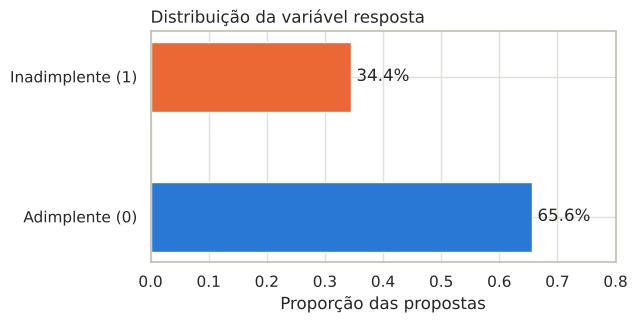

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))
taxa = prata["inadimplente"].value_counts(normalize=True).sort_index()
ax.barh(["Adimplente (0)", "Inadimplente (1)"], taxa.values, color=[AZUL, LARANJA], height=0.5)
for i, v in enumerate(taxa.values):
    ax.text(v + 0.01, i, f"{v:.1%}", va="center")
ax.set_xlim(0, 0.8)
ax.set_xlabel("Proporção das propostas")
ax.set_title("Distribuição da variável resposta", loc="left")
salvar(fig, "01_distribuicao_alvo")
plt.show()

### 4.2 Variáveis numéricas: distribuição por classe

Comparamos a distribuição de cada variável entre adimplentes e inadimplentes. Quanto mais as caixas se **deslocam** uma em relação à outra, mais a variável ajuda a separar as classes.

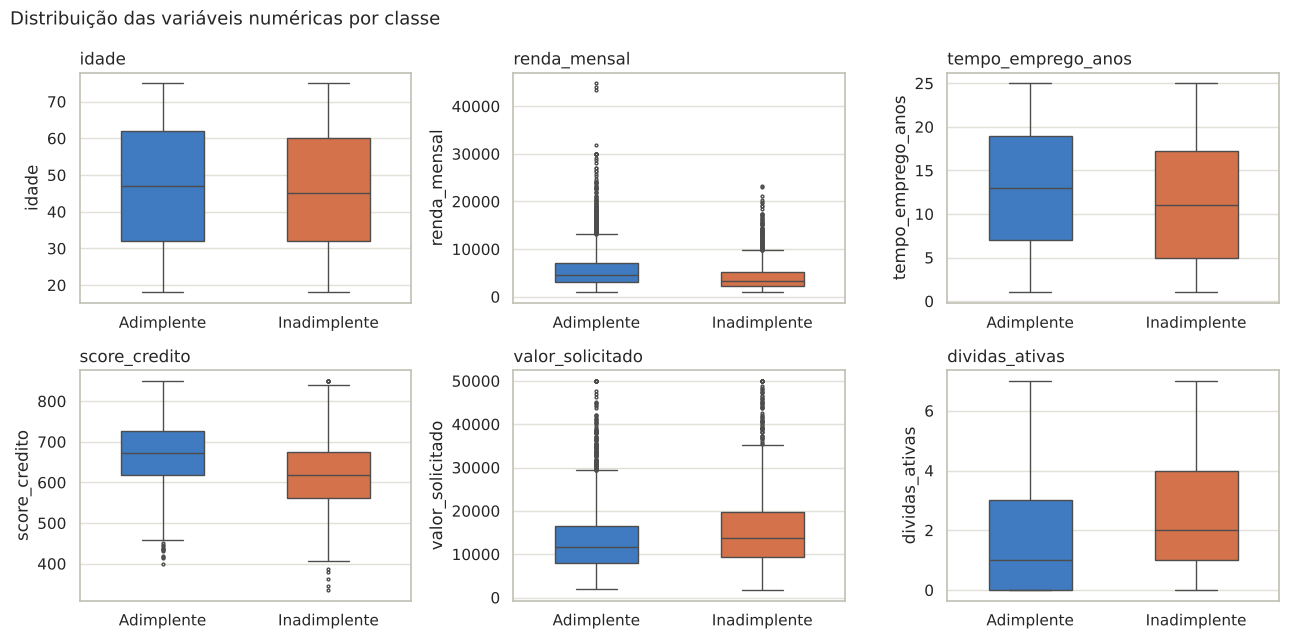

In [16]:
numericas = ["idade", "renda_mensal", "tempo_emprego_anos", "score_credito", "valor_solicitado", "dividas_ativas"]

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.flat, numericas):
    sns.boxplot(data=prata, x="inadimplente", y=col, hue="inadimplente", palette=CORES_CLASSE,
                legend=False, ax=ax, width=0.5, fliersize=2)
    ax.set_xticks([0, 1], ["Adimplente", "Inadimplente"])
    ax.set_xlabel("")
    ax.set_title(col, loc="left")
fig.suptitle("Distribuição das variáveis numéricas por classe", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
salvar(fig, "02_boxplots_numericas")
plt.show()

### 4.3 Taxa de inadimplência por faixa

O boxplot mostra a distribuição. Para o negócio, porém, a pergunta mais direta é: **em cada faixa, qual a taxa de inadimplência?** Dividimos cada variável em 5 faixas com a mesma quantidade de propostas (quintis).

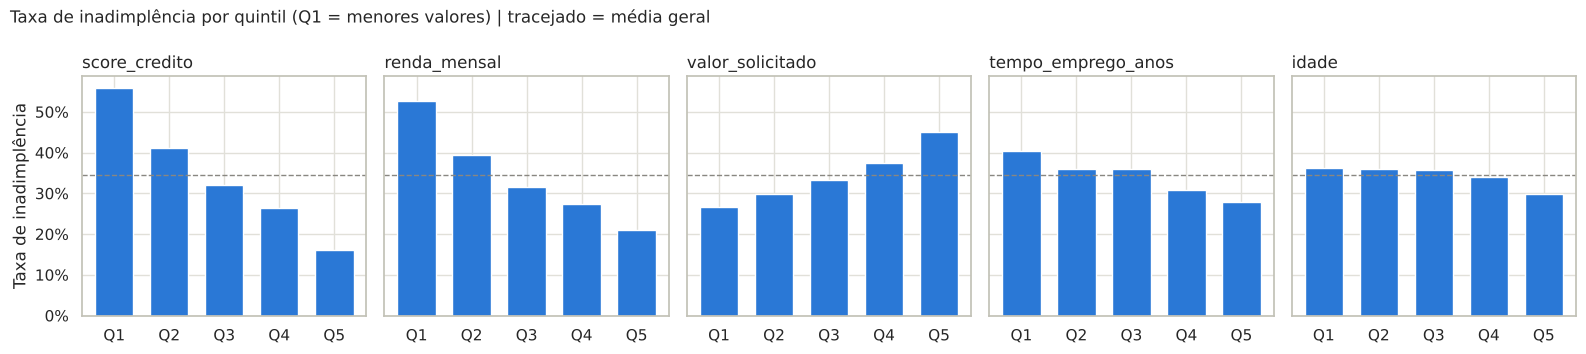

In [17]:
taxa_geral = prata["inadimplente"].mean()
continuas = ["score_credito", "renda_mensal", "valor_solicitado", "tempo_emprego_anos", "idade"]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharey=True)
for ax, col in zip(axes, continuas):
    faixas = pd.qcut(prata[col], 5, duplicates="drop")
    t = prata.groupby(faixas, observed=True)["inadimplente"].mean()
    ax.bar(range(len(t)), t.values, color=AZUL, width=0.7)
    ax.axhline(taxa_geral, color=CINZA, ls="--", lw=1)
    ax.set_xticks(range(len(t)), [f"Q{i+1}" for i in range(len(t))])
    ax.set_title(col, loc="left")
axes[0].set_ylabel("Taxa de inadimplência")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Taxa de inadimplência por quintil (Q1 = menores valores) | tracejado = média geral",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
salvar(fig, "03_taxa_por_quintil")
plt.show()

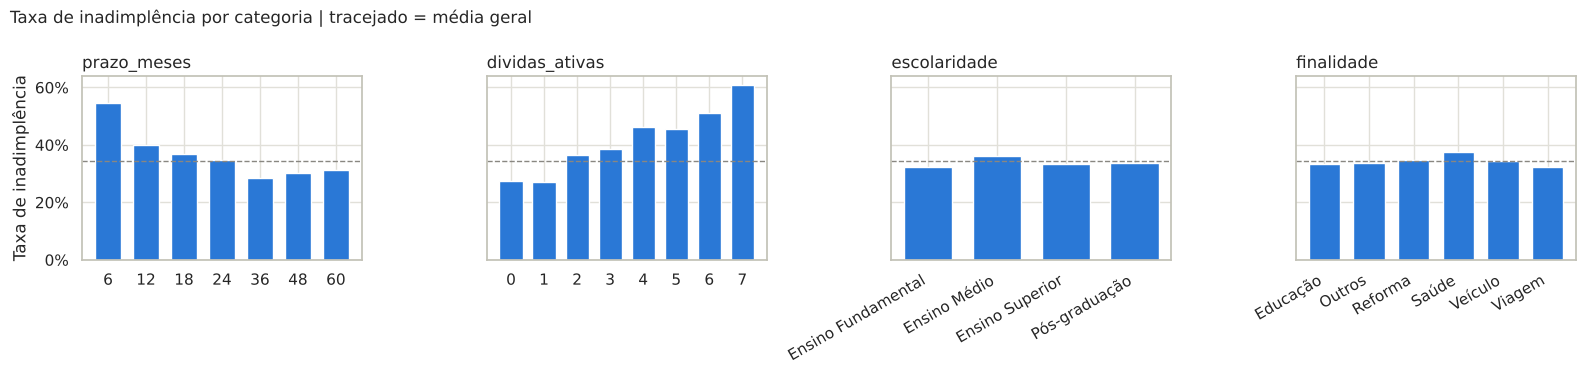

In [18]:
discretas = ["prazo_meses", "dividas_ativas", "escolaridade", "finalidade"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, col in zip(axes, discretas):
    t = prata.groupby(col, observed=True)["inadimplente"].mean()
    ax.bar(range(len(t)), t.values, color=AZUL, width=0.7)
    ax.axhline(taxa_geral, color=CINZA, ls="--", lw=1)
    ax.set_xticks(range(len(t)), [str(i) for i in t.index], rotation=30 if col in ("escolaridade", "finalidade") else 0,
                  ha="right" if col in ("escolaridade", "finalidade") else "center")
    ax.set_title(col, loc="left")
axes[0].set_ylabel("Taxa de inadimplência")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Taxa de inadimplência por categoria | tracejado = média geral", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
salvar(fig, "04_taxa_por_categoria")
plt.show()

### 4.4 Estado: diferença real ou acaso?

Com 27 UFs e cerca de 180 propostas em cada uma, é natural que as taxas variem um pouco **só por acaso**. Usamos o **teste qui-quadrado de independência** para verificar se a diferença entre estados é maior do que o acaso explicaria. Fazemos o mesmo para as outras categóricas.

In [19]:
from scipy.stats import chi2_contingency

resultado = []
for col in ["estado", "escolaridade", "finalidade", "prazo_meses", "dividas_ativas"]:
    tabela = pd.crosstab(prata[col], prata["inadimplente"])
    chi2, p, gl, _ = chi2_contingency(tabela)
    t = prata.groupby(col, observed=True)["inadimplente"].mean()
    resultado.append({"variável": col, "categorias": len(tabela), "menor taxa": f"{t.min():.1%}",
                      "maior taxa": f"{t.max():.1%}", "p-valor": p,
                      "associação significativa (5%)?": "sim" if p < 0.05 else "não"})
tabela_qui2 = pd.DataFrame(resultado).set_index("variável")
tabela_qui2["p-valor"] = tabela_qui2["p-valor"].map(lambda p: "< 0.0001" if p < 1e-4 else f"{p:.4f}")
tabela_qui2

,categorias,menor taxa,maior taxa,p-valor,associação significativa (5%)?
variável,,,,,
estado,27,29.4%,42.2%,0.6014,não
escolaridade,4,32.2%,36.0%,0.2305,não
finalidade,6,32.5%,37.5%,0.5362,não
prazo_meses,7,28.4%,54.5%,< 0.0001,sim
dividas_ativas,8,26.9%,60.8%,< 0.0001,sim


**Como ler o p-valor:** é a probabilidade de observar diferenças tão grandes quanto essas **se, na verdade, a variável não tivesse relação nenhuma** com a inadimplência. Um p-valor abaixo de 5% indica que o acaso dificilmente explica a diferença.

### 4.5 Correlação entre as variáveis numéricas

A correlação também revela **redundância**: duas variáveis explicativas muito correlacionadas trazem quase a mesma informação.

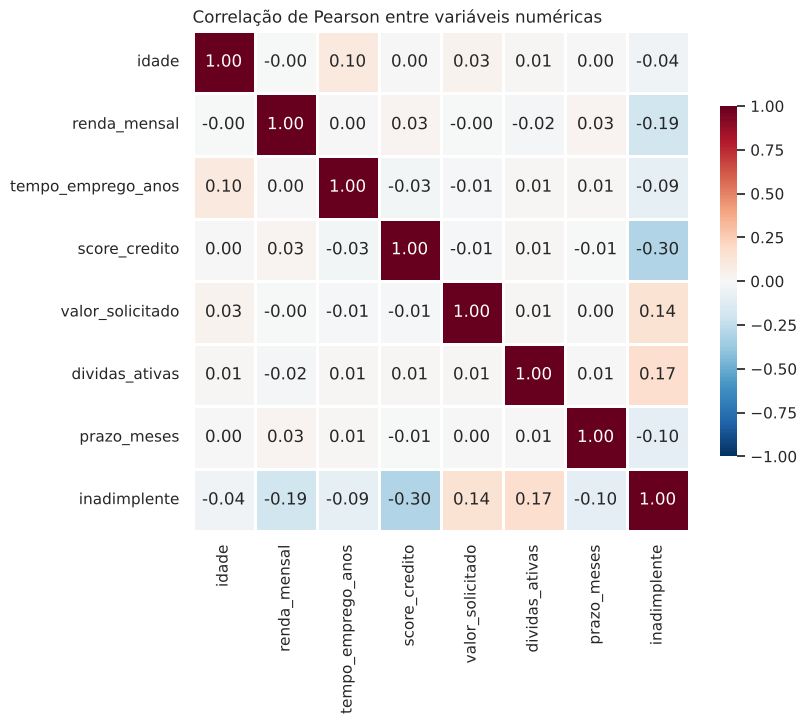

In [20]:
corr = prata[numericas + ["prazo_meses", "inadimplente"]].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlação de Pearson entre variáveis numéricas", loc="left")
salvar(fig, "05_correlacao")
plt.show()

### 4.6 Principais achados da análise exploratória

| # | Achado | Evidência |
|---|---|---|
| 1 | **Score de crédito é o sinal individual mais forte** | A inadimplência cai de ~56% no quintil de menor score para ~16% no de maior score |
| 2 | **Renda maior, menos risco** | De ~53% no 1º quintil de renda para ~21% no 5º |
| 3 | **Valor solicitado maior, mais risco** | De ~27% para ~45% entre o 1º e o 5º quintil |
| 4 | **Mais dívidas ativas, mais risco** | ~27% com 0–1 dívida contra ~61% com 7 dívidas |
| 5 | **Prazos curtos têm mais inadimplência** | ~55% com prazo de 6 meses contra ~28% com 36 meses. É um resultado contraintuitivo, investigado na seção 5 |
| 6 | Idade e tempo de emprego têm efeito **fraco** | Variação pequena, concentrada nas faixas mais altas |
| 7 | **Estado, escolaridade e finalidade não mostram associação significativa** | Teste qui-quadrado com p-valor de 0,23 a 0,60 |
| 8 | **As variáveis explicativas são praticamente independentes entre si** | Correlações entre elas de no máximo 0,10. Não há redundância entre as variáveis originais |

> **Correlação não é causalidade.** Por exemplo, um score baixo não *causa* inadimplência. Ele resume um histórico que também está ligado a ela. O modelo vai usar essas **associações** para estimar risco, sem afirmar relações de causa.

## 5. Engenharia de atributos (prata → 🥇 ouro)

A análise exploratória mostrou um efeito curioso: **prazos curtos têm mais inadimplência**. Uma hipótese de negócio explica isso. Com o mesmo valor, um prazo curto gera uma **parcela maior**, e a parcela pesa mais no orçamento. Nenhuma variável original mede esse "peso no orçamento" diretamente. Por isso vamos criá-la, com a função `criar_atributos` do módulo `src/credair/atributos.py`.

| Variável derivada | Como é construída | O que representa | Hipótese de relação com o risco |
|---|---|---|---|
| `parcela_estimada` | `valor_solicitado / prazo_meses` | Parcela mensal aproximada, **sem juros** | Parcelas maiores são mais difíceis de pagar |
| `comprometimento_renda` | `parcela_estimada / renda_mensal` | **Fração da renda** comprometida com a parcela | Quanto maior o comprometimento, menor a folga e maior o risco |
| `valor_sobre_renda` | `valor_solicitado / renda_mensal` | Quantas rendas mensais vale o empréstimo | Empréstimos grandes para a renda são mais arriscados |

> 🧭 **Decisão: ignorar os juros.** Não temos a taxa de juros na base. A parcela estimada é uma **aproximação**, mas preserva a ordem: quem pede mais em menos tempo tem parcela maior.
>
> 🧭 **Decisão: só transformações linha a linha na camada ouro.** Cada variável nova usa apenas dados **da própria linha**, sem médias ou estatísticas da base. Por isso pode ser calculada antes da divisão treino/teste **sem vazamento de dados** (D06).

In [21]:
from credair import criar_atributos

print(inspect.getsource(criar_atributos))

ouro = criar_atributos(prata)
ouro[["valor_solicitado", "prazo_meses", "renda_mensal", "parcela_estimada",
      "comprometimento_renda", "valor_sobre_renda"]].describe().T

def criar_atributos(df: pd.DataFrame) -> pd.DataFrame:
    # Cria as variáveis derivadas (transformações determinísticas, linha a linha)
    df = df.copy()
    df["parcela_estimada"] = df["valor_solicitado"] / df["prazo_meses"]
    df["comprometimento_renda"] = df["parcela_estimada"] / df["renda_mensal"]
    df["valor_sobre_renda"] = df["valor_solicitado"] / df["renda_mensal"]
    return df



,count,mean,std,min,25%,50%,75%,max
valor_solicitado,"4,981.000","14,260.293","8,267.027","1,721.480","8,466.240","12,363.960","17,763.210","50,000.000"
prazo_meses,"4,981.000",29.913,15.487,6.000,18.000,24.000,36.000,60.000
renda_mensal,"4,971.000","5,238.841","3,968.128",900.000,"2,704.045","4,153.690","6,465.970","44,814.190"
parcela_estimada,"4,981.000",685.923,694.775,44.681,270.384,458.843,832.919,"8,333.333"
comprometimento_renda,"4,971.000",0.200,0.267,0.004,0.056,0.111,0.233,4.024
valor_sobre_renda,"4,971.000",4.128,3.920,0.130,1.666,2.958,5.255,44.070


### 5.1 As novas variáveis ajudam a separar as classes?

Para medir o **poder de separação individual** de cada variável, usamos a **AUC**, a área sob a curva ROC.
- **AUC de 0,5:** a variável não separa as classes; é o mesmo que sortear.
- **AUC de 1,0:** separação perfeita.

Valores abaixo de 0,5 indicam relação **inversa**. Nesse caso, mostramos `1 − AUC` para facilitar a comparação.

In [22]:
from sklearn.metrics import roc_auc_score

candidatas = ["score_credito", "comprometimento_renda", "renda_mensal", "valor_sobre_renda", "dividas_ativas",
              "parcela_estimada", "prazo_meses", "valor_solicitado", "tempo_emprego_anos", "idade"]
linhas = []
for col in candidatas:
    validos = ouro[col].notna()
    auc = roc_auc_score(ouro.loc[validos, "inadimplente"], ouro.loc[validos, col])
    linhas.append({"variável": col, "AUC individual": max(auc, 1 - auc),
                   "direção": "↑ valor, ↑ risco" if auc >= 0.5 else "↑ valor, ↓ risco",
                   "nova?": "✨" if col in ("parcela_estimada", "comprometimento_renda", "valor_sobre_renda") else ""})
auc_individual = pd.DataFrame(linhas).sort_values("AUC individual", ascending=False).set_index("variável")
auc_individual.round(3)

,AUC individual,direção,nova?
variável,,,
score_credito,0.682,"↑ valor, ↓ risco",
comprometimento_renda,0.667,"↑ valor, ↑ risco",✨
valor_sobre_renda,0.664,"↑ valor, ↑ risco",✨
renda_mensal,0.641,"↑ valor, ↓ risco",
parcela_estimada,0.606,"↑ valor, ↑ risco",✨
dividas_ativas,0.596,"↑ valor, ↑ risco",
valor_solicitado,0.584,"↑ valor, ↑ risco",
prazo_meses,0.565,"↑ valor, ↓ risco",
tempo_emprego_anos,0.553,"↑ valor, ↓ risco",


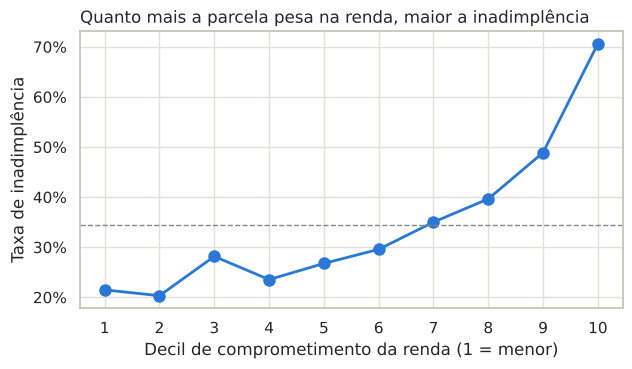

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.6))
faixas = pd.qcut(ouro["comprometimento_renda"], 10)
t = ouro.groupby(faixas, observed=True)["inadimplente"].mean()
ax.plot(range(1, 11), t.values, color=AZUL, lw=2, marker="o", ms=8)
ax.axhline(taxa_geral, color=CINZA, ls="--", lw=1)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Decil de comprometimento da renda (1 = menor)")
ax.set_ylabel("Taxa de inadimplência")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Quanto mais a parcela pesa na renda, maior a inadimplência", loc="left")
salvar(fig, "06_comprometimento_renda")
plt.show()

In [24]:
print("Correlação entre as variáveis derivadas e as originais:")
ouro[["comprometimento_renda", "valor_sobre_renda", "parcela_estimada", "valor_solicitado", "renda_mensal"]].corr().round(2)

Correlação entre as variáveis derivadas e as originais:


,comprometimento_renda,valor_sobre_renda,parcela_estimada,valor_solicitado,renda_mensal
comprometimento_renda,1.000,0.690,0.750,0.410,-0.340
valor_sobre_renda,0.690,1.000,0.340,0.590,-0.470
parcela_estimada,0.750,0.340,1.000,0.550,-0.020
valor_solicitado,0.410,0.590,0.550,1.000,-0.000
renda_mensal,-0.340,-0.470,-0.020,-0.000,1.000


**Resultados da engenharia de atributos:**
- `comprometimento_renda` é a **2ª variável mais discriminante**, com AUC individual de 0,667. Fica logo atrás do score (0,682) e à frente de todas as outras originais.
- O gráfico por decil mostra uma relação **clara e crescente**: de ~21% de inadimplência nos menores comprometimentos para **~71%** no decil mais alto, em que a parcela consome cerca de 45% da renda ou mais.
- **Isso explica o "paradoxo do prazo":** prazos curtos não são arriscados por si mesmos. Eles **geram parcelas maiores**, e é o peso da parcela na renda que eleva o risco.

> 🧭 **Decisão: usar `comprometimento_renda` no modelo e descartar `parcela_estimada` e `valor_sobre_renda`.**
> - `comprometimento_renda` já **combina** valor, prazo e renda numa única medida com significado de negócio.
> - `valor_sobre_renda` tem poder parecido (0,664), mas é correlacionada com ela (0,69) e ignora o prazo. Ficaria redundante.
> - `parcela_estimada` é mais fraca (0,606) e não considera a renda.
> - A contribuição real ao modelo será medida na seção 7 por validação cruzada, comparando o modelo **com e sem** a variável nova.

### 5.2 Salvando a camada ouro

In [25]:
ouro.to_parquet(OURO, index=False)
print(f"Camada ouro salva em {OURO.relative_to(RAIZ)}: {ouro.shape[0]:,} linhas × {ouro.shape[1]} colunas")

Camada ouro salva em data/gold/credito_modelagem.parquet: 4,981 linhas × 14 colunas


## 6. Preparação para modelagem (camada 🥇 ouro)

### 6.1 Seleção das variáveis

Partimos das variáveis **candidatas** e justificamos as exclusões. A escolha final entre as candidatas é feita na seção 7, por validação cruzada.

| Variável | Situação | Motivo |
|---|---|---|
| 7 numéricas originais + `comprometimento_renda` | ✅ candidatas | Relação observada com o risco nas seções 4 e 5 |
| `escolaridade`, `finalidade` | ⚖️ candidatas | Associação fraca e não significativa (qui-quadrado). Vamos testar se acrescentam algo |
| `estado` | ❌ excluída | (1) Sem associação significativa (p = 0,60). (2) Geraria 26 colunas *dummy* com ~180 casos cada, terreno fértil para **sobreajuste**. (3) **Risco ético e regulatório:** usar o local de moradia pode discriminar regiões inteiras. Mesmo assim, testamos na seção 7 para mostrar que não faz falta |
| `parcela_estimada`, `valor_sobre_renda` | ❌ excluídas | Redundantes com `comprometimento_renda` (seção 5) |

In [26]:
# Listas de variáveis definidas em src/credair/config.py
from credair.config import ALVO, CATEGORICAS, EXCLUIDAS, NUMERICAS

X = ouro[NUMERICAS + CATEGORICAS]
y = ouro[ALVO]
print(f"Variáveis no modelo: {len(NUMERICAS)} numéricas + {len(CATEGORICAS)} categóricas")
print(f"Excluídas: {EXCLUIDAS}")

Variáveis no modelo: 8 numéricas + 2 categóricas
Excluídas: ['estado', 'parcela_estimada', 'valor_sobre_renda']


### 6.2 Divisão em treino e teste

> 🧭 **Decisão: 80% para treino e 20% para teste, com estratificação.**
> - O **teste** simula propostas **novas**, que o modelo nunca viu. Ele só é usado **uma vez**, na avaliação final (seção 8).
> - A **estratificação** (`stratify=y`) garante que treino e teste tenham a **mesma proporção** de inadimplentes. Sem ela, um sorteio desfavorável poderia distorcer as métricas.
> - A divisão é feita **antes** de qualquer transformação que aprenda com os dados.

In [27]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
pd.DataFrame({
    "linhas": [len(X_treino), len(X_teste)],
    "taxa de inadimplência": [f"{y_treino.mean():.1%}", f"{y_teste.mean():.1%}"],
}, index=["treino", "teste"])

,linhas,taxa de inadimplência
treino,3984,34.4%
teste,997,34.4%


### 6.3 Pipeline de transformações

A Regressão Logística tem três exigências:

| Exigência | Por quê | Transformação |
|---|---|---|
| Não aceita valores ausentes | Não há como multiplicar um coeficiente por "vazio" | **Imputação pela mediana**, mais robusta a valores extremos que a média |
| Sensível à escala | A regularização penaliza coeficientes; sem escala, renda (milhares) e dívidas (0 a 7) seriam penalizadas de forma desigual. A escala também deixa os coeficientes **comparáveis** entre si | **Padronização** (média 0, desvio 1) |
| Só aceita números | Categorias como "Veículo" precisam virar números | **One-hot encoding**: uma coluna 0/1 por categoria |

> 🧭 **Decisão: tudo dentro de um `Pipeline` com `ColumnTransformer`.** O pipeline garante que a mediana, a média e o desvio usados nas transformações sejam calculados **somente no treino**, e depois **apenas aplicados** ao teste. Isso evita o vazamento de dados. Também garante que, na aplicação futura, uma proposta nova passe exatamente pelas mesmas transformações.
>
> 🧭 **Decisão: `drop="first"` no one-hot.** Removemos uma categoria de referência de cada variável, como Ensino Fundamental e Educação. Assim cada coeficiente se lê como "**em relação à categoria de referência**".

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessador = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("padronizar", StandardScaler()),
    ]), NUMERICAS),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORICAS),
])

# Demonstração: ajusta SOMENTE no treino e aplica no teste
X_treino_t = preprocessador.fit_transform(X_treino)
X_teste_t = preprocessador.transform(X_teste)
nomes = preprocessador.get_feature_names_out()
print(f"Treino transformado: {X_treino_t.shape} | Teste transformado: {X_teste_t.shape}")
print(f"Ausentes após imputação: {np.isnan(X_treino_t).sum()}")
pd.DataFrame(X_treino_t[:5], columns=nomes).round(2)

Treino transformado: (3984, 16) | Teste transformado: (997, 16)
Ausentes após imputação: 0


,num__idade,num__renda_mensal,num__tempo_emprego_anos,num__score_credito,num__valor_solicitado,num__prazo_meses,num__dividas_ativas,num__comprometimento_renda,cat__escolaridade_Ensino Médio,cat__escolaridade_Ensino Superior,cat__escolaridade_Pós-graduação,cat__finalidade_Outros,cat__finalidade_Reforma,cat__finalidade_Saúde,cat__finalidade_Veículo,cat__finalidade_Viagem
0,-1.320,-0.270,1.020,1.290,0.530,-0.390,2.200,-0.040,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.050,1.050,1.020,-2.470,-1.290,-1.170,-1.030,-0.630,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000
2,-1.440,-0.480,-0.500,-0.940,-0.140,1.170,1.130,-0.440,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000
3,0.170,-0.990,-1.470,-1.270,-0.260,0.390,1.130,0.200,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000
4,-1.030,-0.620,0.740,0.970,1.800,0.390,0.590,0.360,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000


## 7. Modelagem

### 7.1 Referências simples (baselines)

Um modelo só tem valor se for **melhor que alternativas simples**. Usamos duas referências:
1. **Classe majoritária:** sempre diz "adimplente". É o piso absoluto.
2. **Regra só com o score:** uma regressão logística com **apenas** `score_credito`. Representa a prática comum de "aprovar por score". Se o modelo completo não superar essa regra, as outras variáveis não estão ajudando.

### 7.2 Validação cruzada para escolher a configuração

> 🧭 **Decisão: comparar configurações com validação cruzada, usando só o treino.** Se usássemos o teste para escolher entre versões do modelo, ele deixaria de ser uma avaliação independente. A validação cruzada estratificada com 5 partes divide o treino em 5 pedaços. Treina em 4, avalia no quinto, e repete 5 vezes. O resultado é uma média e uma medida de **estabilidade** (o desvio).
>
> **Métrica de comparação: ROC-AUC.** Ela mede a capacidade de **ordenar** os clientes do mais arriscado ao menos arriscado, **independentemente do limiar** de decisão. O limiar é discutido na seção 8.

In [29]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

from credair.modelo import modelo_logistico, validacao_cruzada

# Pipeline completo (pré-processamento + regressão logística), definido em src/credair/modelo.py
print(inspect.getsource(modelo_logistico))

cv = validacao_cruzada()
X_treino_completo = ouro.loc[X_treino.index]  # treino com todas as colunas, para testar variações

candidatos = {
    "Classe majoritária (baseline)": (DummyClassifier(strategy="most_frequent"), NUMERICAS),
    "Só score (baseline)": (modelo_logistico(["score_credito"], []), ["score_credito"]),
    "Logística: variáveis originais": (
        modelo_logistico([c for c in NUMERICAS if c != "comprometimento_renda"], CATEGORICAS),
        [c for c in NUMERICAS if c != "comprometimento_renda"] + CATEGORICAS),
    "Logística: + comprometimento_renda": (modelo_logistico(NUMERICAS, CATEGORICAS), NUMERICAS + CATEGORICAS),
    "Logística: + comprometimento + estado": (
        modelo_logistico(NUMERICAS, CATEGORICAS + ["estado"]), NUMERICAS + CATEGORICAS + ["estado"]),
    "Logística: só numéricas + comprometimento": (modelo_logistico(NUMERICAS, []), NUMERICAS),
}

resultados_cv = []
for nome, (modelo, colunas) in candidatos.items():
    notas = cross_val_score(modelo, X_treino_completo[colunas], y_treino, cv=cv, scoring="roc_auc")
    resultados_cv.append({"configuração": nome, "AUC média": notas.mean(), "desvio": notas.std()})
resultados_cv = pd.DataFrame(resultados_cv).set_index("configuração")
resultados_cv.round(3)

def modelo_logistico(numericas, categoricas, **kwargs):
    # Monta o pipeline completo: pré-processamento + regressão logística
    transformadores = [("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                         ("padronizar", StandardScaler())]), numericas)]
    if categoricas:
        transformadores.append(("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categoricas))
    return Pipeline([
        ("preparar", ColumnTransformer(transformadores)),
        ("modelo", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **kwargs)),
    ])



,AUC média,desvio
configuração,,
Classe majoritária (baseline),0.500,0.000
Só score (baseline),0.679,0.017
Logística: variáveis originais,0.769,0.013
Logística: + comprometimento_renda,0.793,0.015
Logística: + comprometimento + estado,0.788,0.015
Logística: só numéricas + comprometimento,0.794,0.016


**Leitura dos resultados da validação cruzada:**
1. Todas as versões da Regressão Logística **superam com folga as duas referências**. A AUC sobe de 0,50 (classe majoritária) e 0,68 (só score) para cerca de 0,79.
2. **A variável criada na seção 5 vale a pena:** acrescentar `comprometimento_renda` eleva a AUC de 0,769 para 0,793. É o maior ganho entre as configurações.
3. **Incluir `estado` não ajuda:** a AUC cai levemente, para 0,788, um sinal de que essas colunas acrescentam ruído.
4. **Retirar `escolaridade` e `finalidade` não piora o modelo**, que fica em 0,794 contra 0,793. As diferenças estão dentro do desvio (±0,015).

> 🧭 **Decisão: modelo final com as 8 variáveis numéricas, incluindo `comprometimento_renda`.** Diante de desempenhos equivalentes, ficamos com o **modelo mais simples** (princípio da parcimônia). Ele é mais fácil de explicar, tem menos risco de sobreajuste e pede menos informação ao cliente. Isso é coerente com o teste qui-quadrado da seção 4, que não encontrou associação dessas categóricas com a inadimplência.
>
> **Regularização:** mantivemos o padrão do scikit-learn (penalização L2, `C = 1`). Com cerca de 4 mil linhas e apenas 8 variáveis, o risco de sobreajuste é baixo, e o desvio pequeno entre as partes da validação cruzada confirma a **estabilidade**.

### 7.3 Treinamento do modelo final

O modelo escolhido é treinado com **todo o conjunto de treino**.

In [30]:
from credair.config import VARIAVEIS_FINAIS  # = NUMERICAS, escolha feita pela validação cruzada acima
modelo_final = modelo_logistico(VARIAVEIS_FINAIS, [])
modelo_final.fit(X_treino[VARIAVEIS_FINAIS], y_treino)

baseline_maioria = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
baseline_score = modelo_logistico(["score_credito"], []).fit(X_treino[["score_credito"]], y_treino)

reg = modelo_final.named_steps["modelo"]
print(f"Modelo treinado com {len(y_treino):,} propostas e {reg.coef_.shape[1]} coeficientes (+ intercepto)")
print("Variáveis:", VARIAVEIS_FINAIS)
print(f"Regularização: L2, C = {reg.C} (padrão do scikit-learn)")

Modelo treinado com 3,984 propostas e 8 coeficientes (+ intercepto)
Variáveis: ['idade', 'renda_mensal', 'tempo_emprego_anos', 'score_credito', 'valor_solicitado', 'prazo_meses', 'dividas_ativas', 'comprometimento_renda']
Regularização: L2, C = 1.0 (padrão do scikit-learn)


## 8. Avaliação e interpretação (conjunto de teste)

Agora, **pela primeira vez**, usamos o conjunto de teste: são 20% das propostas, que o modelo nunca viu.

### 8.1 Métricas no limiar padrão (0,5)

| Métrica | Pergunta que responde |
|---|---|
| **ROC-AUC** | O modelo ordena bem os clientes por risco? (independe do limiar) |
| **Acurácia** | Que fração das previsões está certa? (engana com classes desbalanceadas) |
| **Precisão** | Dos que o modelo marcou como risco, quantos de fato ficaram inadimplentes? |
| **Recall** | Dos inadimplentes reais, quantos o modelo identificou? |
| **F1** | Equilíbrio entre precisão e recall |

In [31]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_curve, precision_recall_curve

from credair import metricas

probs = {
    "Classe majoritária": baseline_maioria.predict_proba(X_teste)[:, 1],
    "Só score": baseline_score.predict_proba(X_teste[["score_credito"]])[:, 1],
    "Regressão Logística": modelo_final.predict_proba(X_teste[VARIAVEIS_FINAIS])[:, 1],
}


tabela_teste = pd.DataFrame({nome: metricas(y_teste, p) for nome, p in probs.items()}).T
tabela_teste.round(3)

,ROC-AUC,Acurácia,Precisão,Recall,F1
Classe majoritária,0.500,0.656,0.000,0.000,0.000
Só score,0.695,0.680,0.585,0.242,0.342
Regressão Logística,0.781,0.737,0.677,0.452,0.542


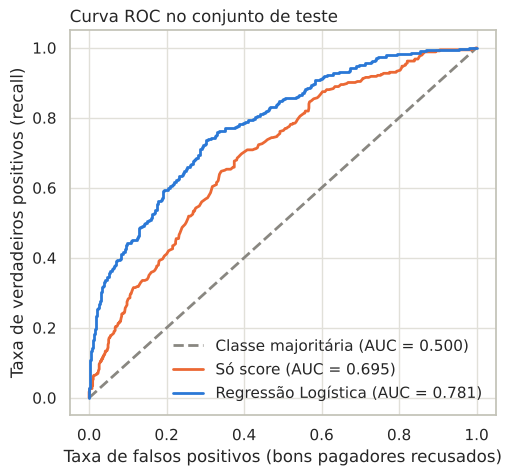

In [32]:
fig, ax = plt.subplots(figsize=(5.5, 5))
estilos = {"Classe majoritária": (CINZA, "--"), "Só score": (LARANJA, "-"), "Regressão Logística": (AZUL, "-")}
for nome, p in probs.items():
    fpr, tpr, _ = roc_curve(y_teste, p)
    cor, ls = estilos[nome]
    ax.plot(fpr, tpr, color=cor, ls=ls, lw=2, label=f"{nome} (AUC = {roc_auc_score(y_teste, p):.3f})")
ax.set_xlabel("Taxa de falsos positivos (bons pagadores recusados)")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.set_title("Curva ROC no conjunto de teste", loc="left")
ax.legend(loc="lower right", frameon=False)
salvar(fig, "07_curva_roc")
plt.show()

### 8.2 Matriz de confusão

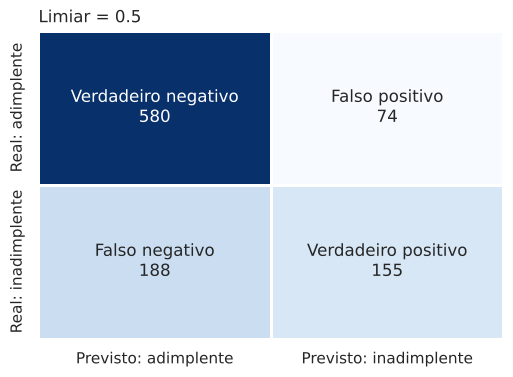

In [33]:
def plot_confusao(y_real, prob, limiar, ax):
    cm = confusion_matrix(y_real, (prob >= limiar).astype(int))
    rotulos = np.array([[f"Verdadeiro negativo\n{cm[0,0]}", f"Falso positivo\n{cm[0,1]}"],
                        [f"Falso negativo\n{cm[1,0]}", f"Verdadeiro positivo\n{cm[1,1]}"]])
    sns.heatmap(cm, annot=rotulos, fmt="", cmap="Blues", cbar=False, linewidths=2, linecolor="white", ax=ax,
                xticklabels=["Previsto: adimplente", "Previsto: inadimplente"],
                yticklabels=["Real: adimplente", "Real: inadimplente"])
    ax.set_title(f"Limiar = {limiar}", loc="left")


fig, ax = plt.subplots(figsize=(6, 4))
plot_confusao(y_teste, probs["Regressão Logística"], 0.5, ax)
salvar(fig, "08_matriz_confusao_05")
plt.show()

**Leitura no limiar padrão (0,5):** o modelo é **conservador**. Quando sinaliza risco, acerta em ~68% dos casos (precisão). Mas identifica **apenas ~45% dos inadimplentes** (recall): mais da metade dos maus pagadores seria aprovada. Na seção 1.4 vimos que esse é o erro **mais caro** para a CredAIR. Por isso vale revisar o limiar.

### 8.3 Escolha do limiar de decisão

O limiar de 0,5 é só uma **convenção**. A pergunta certa para a CredAIR é: **a partir de qual probabilidade de inadimplência vale a pena recusar ou revisar a proposta?** Baixar o limiar aumenta o recall (pegamos mais maus pagadores) e diminui a precisão (recusamos mais bons pagadores).

In [34]:
p_final = probs["Regressão Logística"]
limiares = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6]
linhas = []
for lim in limiares:
    pred = (p_final >= lim).astype(int)
    linhas.append({"limiar": lim,
                   "% propostas sinalizadas": pred.mean(),
                   "precisão": precision_score(y_teste, pred, zero_division=0),
                   "recall": recall_score(y_teste, pred),
                   "F1": f1_score(y_teste, pred)})
tabela_limiar = pd.DataFrame(linhas).set_index("limiar")
(tabela_limiar * 100).round(1).add_suffix(" (%)")

,% propostas sinalizadas (%),precisão (%),recall (%),F1 (%)
limiar,,,,
0.200,63.400,46.500,85.700,60.300
0.250,54.700,49.900,79.300,61.300
0.300,46.500,55.000,74.300,63.200
0.350,40.700,56.700,67.100,61.400
0.400,33.400,61.300,59.500,60.400
0.450,27.900,62.600,50.700,56.000
0.500,23.000,67.700,45.200,54.200
0.600,15.100,78.100,34.400,47.800


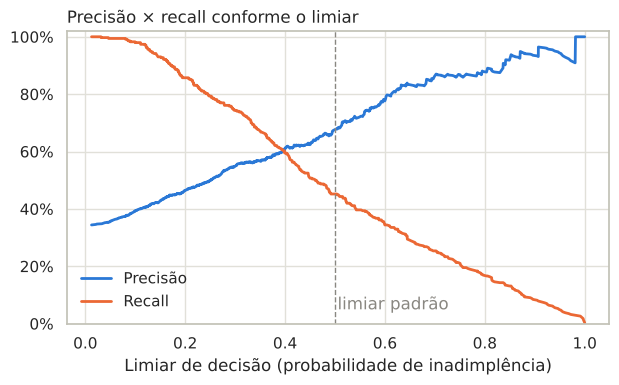

In [35]:
precisao, recall, lims = precision_recall_curve(y_teste, p_final)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(lims, precisao[:-1], color=AZUL, lw=2, label="Precisão")
ax.plot(lims, recall[:-1], color=LARANJA, lw=2, label="Recall")
ax.axvline(0.5, color=CINZA, ls="--", lw=1)
ax.text(0.505, 0.05, "limiar padrão", color=CINZA)
ax.set_xlabel("Limiar de decisão (probabilidade de inadimplência)")
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Precisão × recall conforme o limiar", loc="left")
ax.legend(frameon=False)
salvar(fig, "09_precisao_recall_limiar")
plt.show()

> 🧭 **Decisão: escolher o limiar com dados de treino, e não com o teste.** Se escolhêssemos o limiar olhando a tabela acima, o teste deixaria de ser uma avaliação independente. Usamos as **previsões fora da amostra da validação cruzada** no treino (`cross_val_predict`) e pegamos o limiar que maximiza o **F1**, o equilíbrio entre precisão e recall. Depois, apenas **conferimos** esse limiar no teste.

In [36]:
from credair import escolher_limiar

# Testa limiares de 0,15 a 0,70 nas previsões fora da amostra do treino (src/credair/modelo.py)
LIMIAR_SUGERIDO = escolher_limiar(modelo_logistico(VARIAVEIS_FINAIS, []), X_treino[VARIAVEIS_FINAIS], y_treino, cv=cv)
print(f"Limiar que maximiza o F1 na validação cruzada (treino): {LIMIAR_SUGERIDO:.2f}")

pd.DataFrame({"limiar 0,5": metricas(y_teste, p_final, 0.5),
              f"limiar {LIMIAR_SUGERIDO:.2f}": metricas(y_teste, p_final, LIMIAR_SUGERIDO)}).T.round(3)

Limiar que maximiza o F1 na validação cruzada (treino): 0.31


,ROC-AUC,Acurácia,Precisão,Recall,F1
"limiar 0,5",0.781,0.737,0.677,0.452,0.542
limiar 0.31,0.781,0.709,0.558,0.738,0.636


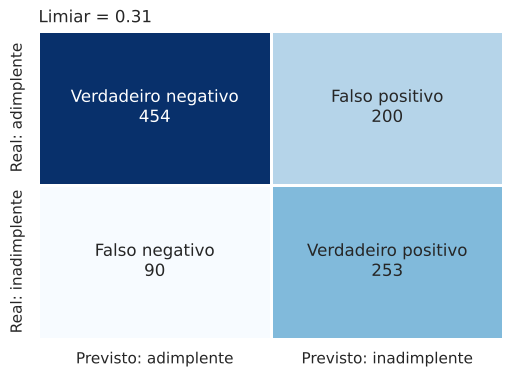

In [37]:
fig, ax = plt.subplots(figsize=(6, 4))
plot_confusao(y_teste, p_final, LIMIAR_SUGERIDO, ax)
salvar(fig, "10_matriz_confusao_sugerido")
plt.show()

**Resultado:** com o limiar de **0,31**, escolhido no treino, o recall no teste sobe de **45% para 74%**. O modelo passa a identificar 3 em cada 4 inadimplentes. Em troca, a precisão cai de 68% para 56%: mais bons pagadores são sinalizados. O F1 melhora de 0,54 para 0,64.

> **O limiar é uma decisão de negócio, não estatística.** O valor ideal depende do custo de cada erro. Um uso sensato **não é recusar automaticamente** todo cliente sinalizado, e sim direcioná-lo para **análise manual** ou para condições diferentes, como prazo maior, valor menor ou garantia. Se a CredAIR souber, por exemplo, que um calote custa 5 vezes mais que um cliente perdido, dá para escolher o limiar que minimiza o custo total.

### 8.4 Quais variáveis mais pesam no resultado?

Na Regressão Logística, cada coeficiente indica como a variável altera o **log-odds** de inadimplência. Para facilitar a leitura, convertemos em **odds ratio** (`e^coef`):
- **Odds ratio > 1:** a variável **aumenta** a chance de inadimplência.
- **Odds ratio < 1:** a variável **diminui** a chance de inadimplência.

Como as variáveis foram padronizadas, o odds ratio se lê como "**o efeito de aumentar a variável em 1 desvio-padrão, mantendo as demais constantes**". Assim dá para comparar variáveis com unidades diferentes.

In [38]:
nomes = modelo_final.named_steps["preparar"].get_feature_names_out()
coefs = pd.DataFrame({
    "variável": [n.split("__", 1)[1] for n in nomes],
    "coeficiente": modelo_final.named_steps["modelo"].coef_[0],
})
coefs["odds ratio"] = np.exp(coefs["coeficiente"])
coefs["efeito"] = np.where(coefs["coeficiente"] > 0, "↑ risco", "↓ risco")
coefs = coefs.reindex(coefs["coeficiente"].abs().sort_values(ascending=False).index).set_index("variável")
coefs.round({"coeficiente": 3, "odds ratio": 2})

,coeficiente,odds ratio,efeito
variável,,,
comprometimento_renda,1.023,2.780,↑ risco
score_credito,-0.828,0.440,↓ risco
dividas_ativas,0.471,1.600,↑ risco
tempo_emprego_anos,-0.263,0.770,↓ risco
renda_mensal,-0.218,0.800,↓ risco
prazo_meses,0.179,1.200,↑ risco
idade,-0.086,0.920,↓ risco
valor_solicitado,0.009,1.010,↑ risco


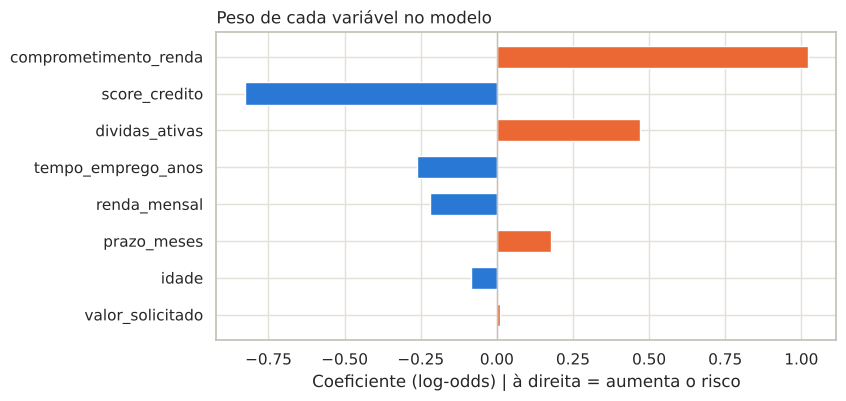

In [39]:
fig, ax = plt.subplots(figsize=(8, 4))
c = coefs["coeficiente"].iloc[::-1]
ax.barh(c.index, c.values, color=[LARANJA if v > 0 else AZUL for v in c.values], height=0.6)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_xlabel("Coeficiente (log-odds) | à direita = aumenta o risco")
ax.set_title("Peso de cada variável no modelo", loc="left")
salvar(fig, "11_coeficientes")
plt.show()

**Interpretação dos coeficientes:**

| Variável | Odds ratio | Leitura (aumento de 1 desvio-padrão, demais constantes) |
|---|---|---|
| `comprometimento_renda` | **2,78** | Comprometer ~27 p.p. a mais da renda **quase triplica** a chance de inadimplência. É o fator de risco **mais forte** |
| `score_credito` | **0,44** | ~85 pontos a mais de score **reduzem a chance pela metade** (−56%). É o fator de proteção mais forte |
| `dividas_ativas` | 1,60 | ~2 dívidas a mais aumentam a chance em 60% |
| `tempo_emprego_anos` | 0,77 | Mais estabilidade no emprego reduz o risco em 23% |
| `renda_mensal` | 0,80 | Mais renda reduz o risco, **além** do efeito que já entra pelo comprometimento |
| `prazo_meses` | 1,20 | ⚠️ **Inverte o sinal** em relação à seção 4 (ver abaixo) |
| `idade`, `valor_solicitado` | ≈ 1 | Efeito próprio quase nulo |

**Por que o prazo "mudou de lado"?** Na análise exploratória, prazos curtos tinham mais inadimplência. No modelo, **mantido o comprometimento constante**, um prazo mais longo aumenta levemente o risco: mais tempo de exposição significa mais chance de imprevistos. O efeito "prazo curto é arriscado" era, na verdade, o efeito da **parcela pesada**, e agora é capturado por `comprometimento_renda`. Da mesma forma, o valor solicitado deixa de ter efeito próprio, porque sua influência já passa pelo comprometimento. Esta é a diferença entre uma **análise univariada**, que olha uma variável de cada vez, e uma **análise multivariada**, que olha o efeito de cada variável **descontando as demais**.

### 8.5 O que isso significa para a CredAIR

- **O modelo ordena bem o risco:** AUC de 0,78 no teste, contra 0,69 da regra só com score. Ele separa melhor bons e maus pagadores do que a prática de aprovar por score.
- **Os resultados no teste (AUC 0,781) estão próximos da validação cruzada (0,794).** Isso indica que o modelo **generaliza**: não decorou o treino.
- **A alavanca mais importante é o comprometimento da renda.** Isso sugere uma ação prática: para clientes no limite, **oferecer prazo maior ou valor menor** reduz a parcela e, com ela, o risco. É melhor do que simplesmente recusar.
- **O modelo é transparente:** cada fator tem uma direção e uma magnitude que fazem sentido de negócio, o que facilita explicar uma decisão ao cliente e ao regulador.

## 9. Conclusão

### 9.1 Principais padrões encontrados nos dados
- A base tinha **problemas de qualidade** a tratar: duplicatas (19), UFs com espaços (101 registros), idades e tempos de emprego impossíveis, e rendas artificiais. Depois do tratamento, ficaram 4.981 propostas, com a **taxa de inadimplência preservada** (34,4%).
- A inadimplência está ligada principalmente a **score, renda, dívidas ativas e ao peso da parcela na renda**.
- **Estado, escolaridade e finalidade** não mostraram associação significativa com o risco.

### 9.2 Principais fatores relacionados à inadimplência
1. **Comprometimento da renda com a parcela** (↑ risco). É a variável criada neste trabalho e o fator mais forte do modelo.
2. **Score de crédito** (↓ risco).
3. **Quantidade de dívidas ativas** (↑ risco).
4. **Tempo de emprego e renda** (↓ risco), com efeito menor.

### 9.3 Resultados do modelo
| Modelo | ROC-AUC (teste) | Recall* |
|---|---|---|
| Classe majoritária | 0,500 | 0% |
| Só score | 0,695 | 24% |
| **Regressão Logística (8 variáveis)** | **0,781** | **45% (limiar 0,5) → 74% (limiar 0,31)** |

\*Recall da classe inadimplente: fração dos maus pagadores identificados.

### 9.4 Limitações
- **Dados sintéticos:** os padrões podem não refletir a realidade de uma financeira.
- **Inconsistência entre idade e tempo de emprego** em ~14% dos registros (P6), mantida por falta de uma regra de correção confiável.
- **Viés de seleção:** a base só contém propostas **analisadas e acompanhadas**. Se a CredAIR já recusava os piores perfis, o modelo nunca viu esses casos (*reject inference*).
- **Parcela estimada sem juros:** é uma aproximação do comprometimento real.
- **Sem dimensão temporal:** não sabemos quando cada proposta ocorreu. Por isso não foi possível validar o modelo "no futuro", treinando no passado e testando em propostas mais recentes.
- **Um único modelo:** o desafio pede Regressão Logística. Modelos não lineares, como árvores e *gradient boosting*, poderiam capturar interações que a logística não vê.

### 9.5 Cuidados para uso em situação real
- **Apoio à decisão, não decisão automática:** propostas sinalizadas devem ir para análise humana ou receber condições ajustadas.
- **Justiça e conformidade:** não usar variáveis que possam discriminar grupos, como `estado`, que já foi excluída. Monitorar taxas de aprovação por grupo e garantir que a decisão possa ser **explicada** ao cliente (LGPD e normas do Banco Central).
- **Monitoramento contínuo:** o perfil dos clientes e a economia mudam (*data drift*). É preciso acompanhar a AUC e a taxa de inadimplência real e **retreinar** o modelo periodicamente.
- **Calibração e limiar:** revisar o limiar com os custos reais de cada erro, definidos junto com a área de crédito.
- **Mesmas regras em produção:** a limpeza, os atributos e o pipeline devem ser **exatamente** os mesmos usados no treino. É o objetivo da próxima etapa do projeto (fase 10): levar essas funções para um módulo testado e reutilizável.